<a href="https://colab.research.google.com/github/priyaaaww/ITA06_LAB_EXP/blob/main/EXP_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First five rows:
   Id   Income  Age  Experience Married/Single House_Ownership Car_Ownership  \
0   1  1303834   23           3         single          rented            no   
1   2  7574516   40          10         single          rented            no   
2   3  3991815   66           4        married          rented            no   
3   4  6256451   41           2         single          rented           yes   
4   5  5768871   47          11         single          rented            no   

            Profession                 CITY           STATE  CURRENT_JOB_YRS  \
0  Mechanical_engineer                 Rewa  Madhya_Pradesh                3   
1   Software_Developer             Parbhani     Maharashtra                9   
2     Technical_writer            Alappuzha          Kerala                4   
3   Software_Developer          Bhubaneswar          Odisha                2   
4        Civil_servant  Tiruchirappalli[10]      Tamil_Nadu                3   

   CURRENT_HOUSE_YRS 

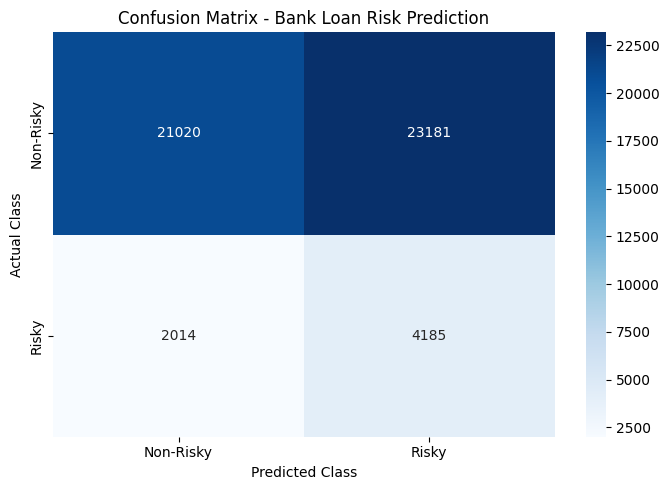

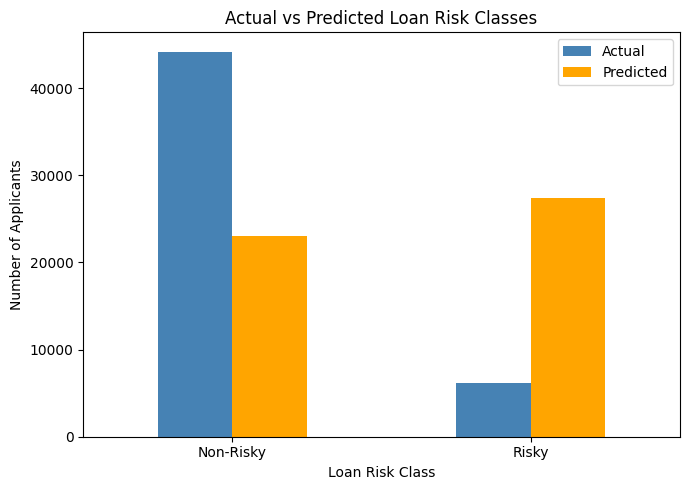

In [1]:
# Bank Loan Risk Prediction using Naive Bayes

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# ---------------------------------------------------
# 1. Load the uploaded dataset
# ---------------------------------------------------
file_path = "/content/Loan Prediction.csv"
df = pd.read_csv(file_path)

print("First five rows:")
print(df.head())

print("\nDataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nRisk Flag distribution:")
print(df["Risk_Flag"].value_counts())

# ---------------------------------------------------
# 2. Separate input features and target
# ---------------------------------------------------

# Id is only an identification number, so it is removed
X = df.drop(columns=["Id", "Risk_Flag"])
y = df["Risk_Flag"]

# Identify numerical and categorical columns
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

# ---------------------------------------------------
# 3. Split dataset into training and testing sets
# ---------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTraining records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

# ---------------------------------------------------
# 4. Data preprocessing
# ---------------------------------------------------

# Scale numerical data and encode categorical data
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numerical_columns),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_columns
        )
    ]
)

# ---------------------------------------------------
# 5. Create Naive Bayes model pipeline
# ---------------------------------------------------
model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("classifier", GaussianNB())
    ]
)

# ---------------------------------------------------
# 6. Train the model
# ---------------------------------------------------
model.fit(X_train, y_train)

# ---------------------------------------------------
# 7. Make predictions
# ---------------------------------------------------
y_pred = model.predict(X_test)

# ---------------------------------------------------
# 8. Evaluate the model
# ---------------------------------------------------
accuracy = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)

print("\n========================================")
print("BANK LOAN RISK PREDICTION RESULTS")
print("========================================")

print(f"\nAccuracy: {accuracy * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Non-Risky", "Risky"],
        zero_division=0
    )
)

# ---------------------------------------------------
# 9. Plot confusion matrix
# ---------------------------------------------------
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Non-Risky", "Risky"],
    yticklabels=["Non-Risky", "Risky"]
)

plt.title("Confusion Matrix - Bank Loan Risk Prediction")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.show()

# ---------------------------------------------------
# 10. Plot actual and predicted class distribution
# ---------------------------------------------------
comparison = pd.DataFrame({
    "Actual": y_test.value_counts().sort_index(),
    "Predicted": pd.Series(y_pred).value_counts().sort_index()
}).fillna(0)

comparison.index = ["Non-Risky", "Risky"]

comparison.plot(
    kind="bar",
    figsize=(7, 5),
    color=["steelblue", "orange"]
)

plt.title("Actual vs Predicted Loan Risk Classes")
plt.xlabel("Loan Risk Class")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()